# Spectral (FFT) Gridding: Cost, Resolution and What You Get For It

**`radar-palette` · ARM BNF C-SAPR2 · 8 August 2026**

---

A radar volume samples a set of curved cones, not a Cartesian box. Turning one into a
3-D grid is therefore an interpolation problem with a choice of operator:

| `method=` | What it does |
| --- | --- |
| `"pyart"` | Barnes-weighted objective analysis — a distance-weighted **average** of nearby gates |
| `"spectral"` | Band-limited evaluation of each sweep on its own cone, then vertical assembly |

The average cannot exceed its inputs, so it is safe but smooths. The spectral operator
is exact where the sampling supports it, but a band-limited interpolant rings at a
discontinuity.

This notebook measures the **cost** of that choice across a resolution ramp on **two
domains**, and shows what the two operators produce at the same resolution.

| Domain | Extent | Why |
| --- | --- | --- |
| zoom | 60 x 60 km on the convective core | matches the advection notebooks; the analysis case |
| full | largest square inscribed in the radar's **unambiguous** range circle | spans enough cells to expose the true scaling, and reaches past the last recorded gate |

Both are needed. The zoom domain is too small to load either method, and reading the
scaling from it alone would give the wrong answer -- as shown below.

One setting is load-bearing throughout: the Barnes radius of influence. Py-ART's default
`roi_func="dist_beam"` is a nearly fixed length, and the vertical separation between
adjacent tilts grows with range, so past a certain range it cannot reach a gate at all.
Everything below uses a radius that grows with height instead. That choice changes the
crossover resolution, the hole counts, and which operator covers more of the domain, so
it is stated in the code rather than left to the defaults.

## 1. Volume and region

Same case as the advection notebooks, and the same 60 × 60 km window on the convective
core so the three are directly comparable.

In [1]:
# radar-palette is not on PyPI yet:
#   pip install git+https://github.com/DIGR-Legacy/radar-palette.git

import os
import time

import numpy as np
import pandas as pd
import pyart

from radar_palette.gridding import grid_volume

LOCAL = "/Users/scollis/data/REAL/bnf_advection/case_20260808_1755"
DATADIR = LOCAL if os.path.isdir(LOCAL) else "data"
VOLUME = os.path.join(DATADIR, "bnfcsapr2cfrS3.a1.20260808.175537.nc")

radar = pyart.io.read(VOLUME)
print(f"{radar.nsweeps} sweeps, {radar.nrays} rays, {radar.ngates} gates")
print(f"elevations {radar.fixed_angle['data'].min():.1f} to "
      f"{radar.fixed_angle['data'].max():.1f} deg, "
      f"max range {radar.range['data'][-1] / 1e3:.0f} km")

# Centre the window on the >40 dBZ core of the lowest sweep.
sweep0 = np.ma.filled(radar.fields["reflectivity"]["data"].astype(float), np.nan)[
    radar.get_slice(0)]
gate_x, gate_y, _ = radar.get_gate_x_y_z(0)
core = np.isfinite(sweep0) & (sweep0 > 40)
CX, CY = float(np.mean(gate_x[core])), float(np.mean(gate_y[core]))
HALF = 30_000.0
print(f"\ncore centre {CX / 1e3:+.1f}, {CY / 1e3:+.1f} km from radar "
      f"({int(core.sum())} gates > 40 dBZ)")

# Two domains. The full one is the largest square inside the radar circle: half-width
# R/sqrt(2), so its corners land on the range ring.
#
# WHICH R, though. The datastream stops recording at range[-1], but the radar is
# unambiguous out to c*PRT/2 -- here 7.5 km further. The instrument's limit is the
# physically meaningful one, so the domain is sized on that; the recorded limit is
# kept because the band between them is where the two operators disagree most.
R_RECORDED = float(radar.range["data"][-1])
PRT = float(np.unique(radar.instrument_parameters["prt"]["data"])[0])
R_UNAMBIGUOUS = 299_792_458.0 * PRT / 2
FULL_HALF = R_UNAMBIGUOUS / np.sqrt(2)
print(f"\nrecorded range    {R_RECORDED / 1e3:.2f} km ({radar.ngates} gates)")
print(f"unambiguous range {R_UNAMBIGUOUS / 1e3:.2f} km (PRT {PRT * 1e6:.1f} us)")
print(f"  the datastream is truncated {(R_UNAMBIGUOUS - R_RECORDED) / 1e3:.2f} km short")

DOMAINS = {
    "zoom": {"cx": CX, "cy": CY, "half": HALF},
    "full": {"cx": 0.0, "cy": 0.0, "half": FULL_HALF},
}
for name, d in DOMAINS.items():
    print(f"{name:5s} {2 * d['half'] / 1e3:6.1f} km square, centred "
          f"({d['cx'] / 1e3:+6.1f}, {d['cy'] / 1e3:+5.1f}) km")
print(f"\nfull-domain corner at {np.hypot(FULL_HALF, FULL_HALF) / 1e3:.1f} km "
      f"= the unambiguous range")

15 sweeps, 13953 rays, 1050 gates
elevations 1.5 to 42.0 deg, max range 113 km

core centre -22.7, -2.0 km from radar (8870 gates > 40 dBZ)

recorded range    113.35 km (1050 gates)
unambiguous range 120.88 km (PRT 806.5 us)
  the datastream is truncated 7.54 km short
zoom    60.0 km square, centred ( -22.7,  -2.0) km
full   171.0 km square, centred (  +0.0,  +0.0) km

full-domain corner at 120.9 km = the unambiguous range


## 2. How the spectral operator works

Before any timings, here is what `method="spectral"` actually does. The short version:
**the range axis gets an FFT, the azimuth axis gets an inverse problem.**

![Spectral gridding pipeline. Left: the stages from raw volume to 3-D grid. Right, top:
the measured offset of every ray from a perfect lattice for the lowest tilt of this
volume, against the tolerance for calling a sweep "uniform". Right, bottom: the
conjugate-gradient residual, one point per solve.](figures/spectral_algorithm_flowchart.png)

### Why not simply take an FFT?

A textbook FFT needs samples on a perfectly even lattice. Range nearly qualifies and
azimuth does not, so the two axes are handled differently.

**Range is evenly spaced but not periodic.** A Fourier series assumes the signal wraps
around — that the last gate neighbours the first. That is false for range, and the
artificial jump at the seam would dominate the error for any ray with a trend in range.
The fix is to mirror the ray before transforming, extending 1050 gates to 2098, so the
extended signal is continuous. The interpolant still passes exactly through every
measured gate.

**Azimuth is not on a lattice at all.** A real antenna does not deliver rays at exactly
even angles. In this volume the rays sit up to 1.1 ray-spacings away from an ideal
lattice, against a tolerance of 0.01 for calling a sweep uniform — the top-right panel
shows every ray of the lowest tilt, and 98% of them fall outside that band. All 15 cones
here classify as `NON_UNIFORM`, so **the plain-FFT path is never taken on this data**.

Recovering the even lattice is therefore not a transform but a solve, for the lattice
coefficients $c$ that best explain the measured rays $f$:

$$(E^{H}WE)\,c = E^{H}Wf$$

by conjugate gradients, with a Kaiser–Bessel NUFFT supplying the forward and adjoint
operators and $W$ the sampling-density weights.

### Why solve rather than grid-and-transform?

Convolution gridding — weight by density, spread with a kernel, FFT, deapodise — is the
usual shortcut, and it computes the **adjoint** of the sampling operator rather than its
inverse. The difference is not academic. On a field with no true energy above azimuthal
mode 7, plain gridding places 2% of the DC amplitude into mode 177: fine-scale structure
that is not in the data.

Two self-checks make the solve trustworthy, both recorded in the evaluator's report:

| Check | Value on this volume | Why it matters |
| --- | --- | --- |
| adjoint test | 9.85 × 10⁻¹⁶ | conjugate gradients is only valid if the adjoint really is the transpose of the forward operator; machine zero confirms it |
| CG residual | 2.6 × 10⁻² → 1.0 × 10⁻⁵ in 12 iterations | the solve converges |

The residual is **not monotone** — it bottoms at 2.7 × 10⁻⁶ by iteration 10 and drifts
up slightly by the default 12, visible in the lower-right panel. At these magnitudes it
does not matter for the result, but it means the default is marginally past the optimum
for this volume rather than still descending.

### Then the vertical stage

Each tilt is now a smooth surface on a curved cone. Because the cones curve, the heights
and the gaps between them differ from column to column, so interpolation runs per column
between the two cones that bracket each target height, shape-preserving in $z$ (PCHIP).

Nothing is extrapolated. A target below the lowest cone, above the highest, or inside a
hole in the tilt run is left empty and flagged with the reason. That policy is what
produces the circular edge on a low horizontal slice: the disc ends exactly where the
lowest beam climbs through the slice height, which is measured directly in section 9.

### What this buys, and what it costs

Interpolating rather than averaging means the operator does not smooth — but a
band-limited interpolant overshoots at a discontinuity, which is Gibbs behaviour and not
a defect in the implementation. On a synthetic hard edge the overshoot reaches +19.8 dB
above the data maximum and −10.6 dB below its minimum, and the two directions are not
symmetric. Everything from section 6 onward measures that trade-off on real data.


In [2]:
# Every figure quoted in the prose above, measured here rather than asserted.
from radar_palette.gridding import (SweepSpectralEvaluator, census_radar, dedup_sweeps,
                                    fill_sweep, AZ_DEV_TOL_FRAC, DEFAULT_CG_ITERATIONS)
from radar_palette.gridding import nufft as _nufft

cones = dedup_sweeps(census_radar(radar))
classes = {geometry.sweep_class for geometry in cones}
deviations = np.array([geometry.az_max_dev_frac for geometry in cones])
print(f"cones after de-duplicating split cuts: {len(cones)}")
print(f"sampling classes present:              {sorted(str(c) for c in classes)}")
print(f"azimuth offset from a perfect lattice: "
      f"{deviations.min():.2f}-{deviations.max():.2f} ray spacings "
      f"(tolerance {AZ_DEV_TOL_FRAC})")

lowest = cones[0]
sweep_slice = radar.get_slice(lowest.sweep)
azimuths = radar.azimuth["data"][sweep_slice].astype(float)
values = np.ma.filled(
    radar.fields["reflectivity"]["data"].astype(float), np.nan)[sweep_slice]

# Reproduce the classifier's own lattice: a full circle is forced to close, so the
# only free parameter is the starting azimuth. A free-slope fit gives a different
# number and would not match what the census reports.
unwrapped = np.rad2deg(np.unwrap(np.deg2rad(azimuths % 360.0)))
ray_index = np.arange(unwrapped.size, dtype=float)
ideal_spacing = np.sign(unwrapped[-1] - unwrapped[0]) * 360.0 / unwrapped.size
start = float(np.mean(unwrapped - ray_index * ideal_spacing))
offsets = np.abs(unwrapped - (start + ray_index * ideal_spacing)) / abs(ideal_spacing)
print(f"\nlowest tilt ({lowest.fixed_angle:.1f} deg, {lowest.nrays} rays):")
print(f"  max offset      {offsets.max():.2f} spacings, matching the census")
print(f"  outside +/-{AZ_DEV_TOL_FRAC}   {100 * (offsets > AZ_DEV_TOL_FRAC).mean():.0f}% of rays")

filled = fill_sweep(values, method="edge")
evaluator = SweepSpectralEvaluator(filled, lowest, azimuths)
extras = evaluator.report.extras
print(f"  range extension {values.shape[1]} -> {evaluator.Nr} gates "
      f"(mirror, 2N-2 = {2 * values.shape[1] - 2})")
print(f"  adjoint test    {extras['adjoint_test_rel']:.2e}  (transpose exact to machine zero)")
print(f"  CG residual     {extras['cg_resid_start']:.1e} -> {extras['cg_resid_end']:.1e} "
      f"in {extras['cg_iters_run']} iterations")

# The residual is not monotone: sweep the iteration count to show where it bottoms.
operator = _nufft._AzimuthNufftOperator(azimuths, lowest)
# The gap-filled array, not the raw one: a NaN anywhere propagates through the solve
# and every residual comes back NaN.
trajectory = [operator.solve(filled, n_cg=k)[1]["cg_resid_end"] for k in range(1, 13)]
best = int(np.argmin(trajectory)) + 1
print(f"  best residual   {min(trajectory):.1e} at {best} iterations, rising to "
      f"{trajectory[-1]:.1e} by the default {DEFAULT_CG_ITERATIONS}")


cones after de-duplicating split cuts: 15
sampling classes present:              ['NON_UNIFORM']
azimuth offset from a perfect lattice: 0.27-1.12 ray spacings (tolerance 0.01)

lowest tilt (1.5 deg, 931 rays):
  max offset      0.73 spacings, matching the census
  outside +/-0.01   98% of rays
  range extension 1050 -> 2098 gates (mirror, 2N-2 = 2098)
  adjoint test    9.85e-16  (transpose exact to machine zero)
  CG residual     2.6e-02 -> 1.0e-05 in 12 iterations
  best residual   2.7e-06 at 10 iterations, rising to 1.0e-05 by the default 12


## 3. Echo top sets the grid top

Gridding to a fixed height either wastes cells on empty air or truncates the storm. A
coarse scout grid — 1 km vertical, a couple of seconds — answers it from the data.

The criterion matters. Taking the highest level with *any* echo picks up sidelobe
contamination; requiring a minimum number of cells does not.

In [3]:
# roi_func is the consequential argument for the "pyart" backing, and the default is
# not a neutral choice. A radius of influence is a fixed length while the separation
# between adjacent tilts grows with range, so with roi_func="dist_beam" no gate is in
# reach beyond a certain range and columns develop interior holes -- 570 of them in one
# section of this volume, with Py-ART's own defaults doing the same. A radius that grows
# with height reaches across the separation. See the radar_palette.gridding module
# docstring for the measured coverage-versus-peak trade-off.
BARNES_KW = dict(fields=["reflectivity"], weighting_function="Barnes2",
                 roi_func="dist", z_factor=0.10, xy_factor=0.02, min_radius=500.0)
SPECTRAL_KW = dict(field_name="reflectivity")
MIN_CELLS = 25
Z_BOT = 500.0

def echo_top_for(domain, verbose=False):
    """Grid top from a coarse scout: highest level holding a robust amount of echo."""
    started = time.time()
    scout = grid_volume(
        radar, grid_shape=(16, 81, 81),
        grid_limits=((500., 16_000.),
                     (domain["cy"] - domain["half"], domain["cy"] + domain["half"]),
                     (domain["cx"] - domain["half"], domain["cx"] + domain["half"])),
        method="pyart", **BARNES_KW)
    values = np.ma.filled(scout.fields["reflectivity"]["data"].astype(float), np.nan)
    levels = scout.z["data"]
    counts = [int(np.nansum(values[i] > 10)) for i in range(len(levels))]
    if verbose:
        for height, n in zip(levels, counts):
            print(f"    {height / 1e3:5.1f} km  {n:6d} cells > 10 dBZ")
    robust = max(h for h, n in zip(levels, counts) if n >= MIN_CELLS)
    loose = max(h for h, n in zip(levels, counts) if n > 0)
    return robust, loose, time.time() - started

for name, domain in DOMAINS.items():
    robust, loose, elapsed = echo_top_for(domain, verbose=(name == "zoom"))
    domain["z_top"] = robust + 2000.0
    domain["limits"] = ((Z_BOT, domain["z_top"]),
                        (domain["cy"] - domain["half"], domain["cy"] + domain["half"]),
                        (domain["cx"] - domain["half"], domain["cx"] + domain["half"]))
    print(f"\n{name:5s} scout {elapsed:.1f} s | echo top >= {MIN_CELLS} cells: "
          f"{robust / 1e3:.1f} km | any cell: {loose / 1e3:.1f} km (sidelobe)")
    print(f"      grid {Z_BOT / 1e3:.1f} to {domain['z_top'] / 1e3:.1f} km")

      0.5 km    2582 cells > 10 dBZ
      1.5 km    2554 cells > 10 dBZ
      2.6 km    2790 cells > 10 dBZ
      3.6 km    2896 cells > 10 dBZ
      4.6 km    2596 cells > 10 dBZ
      5.7 km    2088 cells > 10 dBZ
      6.7 km    1909 cells > 10 dBZ
      7.7 km    1833 cells > 10 dBZ
      8.8 km    1751 cells > 10 dBZ
      9.8 km    1403 cells > 10 dBZ
     10.8 km     803 cells > 10 dBZ
     11.9 km     373 cells > 10 dBZ
     12.9 km     155 cells > 10 dBZ
     13.9 km      55 cells > 10 dBZ
     15.0 km      21 cells > 10 dBZ
     16.0 km       5 cells > 10 dBZ

zoom  scout 3.1 s | echo top >= 25 cells: 13.9 km | any cell: 16.0 km (sidelobe)
      grid 0.5 to 15.9 km

full  scout 3.1 s | echo top >= 25 cells: 11.9 km | any cell: 16.0 km (sidelobe)
      grid 0.5 to 13.9 km


## 4. The resolution ramp

Ten steps from 2000 m to 250 m, isotropic, both methods, **both domains**, plus one
finer step at 200 m on the full domain where the two methods are closest.

This takes about half an hour, almost all of it in Barnes at the fine end.


In [4]:
def grid_shape_for(domain, resolution_m):
    """Isotropic lattice covering the domain at the given resolution."""
    nz = int(round((domain["z_top"] - Z_BOT) / resolution_m)) + 1
    ny = nx = int(round(2 * domain["half"] / resolution_m)) + 1
    return nz, ny, nx

import gc

def time_grid(method, shape, limits, ceiling=None):
    """Wall time for one grid, re-measured once if it looks contaminated.

    A wall-clock timing is the cost plus whatever else the machine was doing, and over a
    long ramp an unrelated transient occasionally lands on one point. Two runs of this
    notebook saw it: a spectral step reporting ~936 s where the same call takes ~37 s,
    and a Barnes step reporting 1770 s against 581 s. Nothing algorithmic distinguishes
    a contaminated point from a real one, so a single measurement cannot be trusted.

    `ceiling` is a physically-motivated upper bound from the previous point: neither
    operator can be worse than linear in output cells, so a step that costs more than
    twice what linear scaling predicts is contaminated rather than expensive. Contention
    only ever adds time, so the minimum of repeats is the better estimate.
    """
    kwargs = BARNES_KW if method == "pyart" else SPECTRAL_KW

    def once():
        started = time.time()
        grid = grid_volume(radar, grid_shape=shape, grid_limits=limits,
                           method=method, **kwargs)
        return time.time() - started, grid

    elapsed, grid = once()
    retried = False
    if ceiling is not None and elapsed > ceiling:
        del grid
        gc.collect()
        again, grid = once()
        retried = True
        elapsed = min(elapsed, again)
    values = np.ma.filled(grid.fields["reflectivity"]["data"].astype(float), np.nan)
    filled = float(np.isfinite(values).mean())
    peak = float(np.nanmax(values)) if np.isfinite(values).any() else np.nan
    del grid, values
    # Release before timing the next step. Without this the previous grid is still
    # resident when the largest one allocates, and the 200 m Barnes step reads 883 s
    # against a true 92 s -- a memory-pressure artefact, not algorithmic cost.
    gc.collect()
    return elapsed, filled, peak, retried


# Neither operator can be worse than linear in output cells, so twice the linear
# prediction from the previous point is a generous bound on a genuine measurement.
CONTAMINATION_FACTOR = 2.0

RESOLUTIONS = np.linspace(2000.0, 250.0, 10)
# The full domain gets one extra, finer point at 200 m: with a radius of influence that
# actually spans the cone separation, Barnes is already the slower operator by 250 m, so
# the extra step measures how fast the gap widens rather than locating the crossover.
EXTRA_FULL = [200.0]

records = []
retries = []
for name, domain in DOMAINS.items():
    # One untimed call per method: the first invocation pays import and cache costs
    # that would otherwise appear as a spurious bump at the coarse end.
    for method in ("pyart", "spectral"):
        time_grid(method, grid_shape_for(domain, 2000.0), domain["limits"])
    print(f"--- {name} domain, {2 * domain['half'] / 1e3:.0f} km square ---")
    steps = list(RESOLUTIONS) + (EXTRA_FULL if name == "full" else [])
    previous = {}
    for resolution in steps:
        shape = grid_shape_for(domain, resolution)
        cells = int(np.prod(shape))
        row = {"domain": name, "res_m": resolution, "cells": cells,
               "nz": shape[0], "ny": shape[1], "nx": shape[2]}
        for method in ("pyart", "spectral"):
            ceiling = None
            if method in previous:
                prior_cells, prior_time = previous[method]
                linear = prior_time * cells / prior_cells
                ceiling = CONTAMINATION_FACTOR * linear
            elapsed, filled, peak, retried = time_grid(
                method, shape, domain["limits"], ceiling=ceiling)
            row[f"{method}_s"], row[f"{method}_filled"] = elapsed, filled
            row[f"{method}_max"] = peak
            previous[method] = (cells, elapsed)
            if retried:
                retries.append((name, resolution, method))
        records.append(row)
        print(f"  {resolution:6.0f} m {row['cells']:11,d} cells   "
              f"barnes {row['pyart_s']:7.2f} s   spectral {row['spectral_s']:6.2f} s")
if retries:
    print(f"\nre-measured {len(retries)} point(s) exceeding the linear ceiling: {retries}")

ramp = pd.DataFrame(records)


--- zoom domain, 60 km square ---
    2000 m       8,649 cells   barnes    1.63 s   spectral  41.21 s
    1806 m      11,560 cells   barnes    1.67 s   spectral  41.56 s
    1611 m      15,884 cells   barnes    1.74 s   spectral  41.95 s
    1417 m      22,188 cells   barnes    1.79 s   spectral  41.47 s
    1222 m      35,000 cells   barnes    1.91 s   spectral  41.82 s
    1028 m      55,696 cells   barnes    2.12 s   spectral  42.15 s
     833 m     106,580 cells   barnes    2.58 s   spectral  41.72 s
     639 m     225,625 cells   barnes    3.64 s   spectral  41.55 s
     444 m     665,856 cells   barnes    7.59 s   spectral  41.63 s
     250 m   3,659,103 cells   barnes   33.76 s   spectral  42.36 s
--- full domain, 171 km square ---
    2000 m      59,168 cells   barnes    2.55 s   spectral  41.83 s
    1806 m      73,728 cells   barnes    2.74 s   spectral  41.68 s
    1611 m     103,041 cells   barnes    3.12 s   spectral  41.80 s
    1417 m     148,840 cells   barnes    3.71 s

## 5. Scaling: the domain you test on changes the answer

The naive expectation is that both methods scale with the number of output cells.
Measured on the zoom domain alone you would conclude that neither does -- and for Barnes
that conclusion is an artefact of too small a domain.


In [5]:
for name in DOMAINS:
    sub = ramp[ramp.domain == name]
    span = sub.cells.iloc[-1] / sub.cells.iloc[0]
    print(f"--- {name} domain: {sub.cells.iloc[0]:,d} to {sub.cells.iloc[-1]:,d} cells "
          f"({span:.0f}x) ---")
    for method in ("pyart", "spectral"):
        t = sub[f"{method}_s"]
        exponent = np.polyfit(np.log(sub.cells), np.log(t), 1)[0]
        print(f"  {method:9s} {t.iloc[0]:6.2f} -> {t.iloc[-1]:6.2f} s "
              f"({t.iloc[-1] / t.iloc[0]:5.1f}x)   mean d(log t)/d(log cells) = {exponent:+.3f}")
    print()

# Barnes is convex in log-log, so a single exponent understates the fine end.
sub = ramp[ramp.domain == "full"]
local = [np.log(sub.pyart_s.iloc[k + 1] / sub.pyart_s.iloc[k]) /
         np.log(sub.cells.iloc[k + 1] / sub.cells.iloc[k]) for k in range(len(sub) - 1)]
print("Barnes local exponent per segment, full domain (coarse -> fine):")
print("  " + "  ".join(f"{v:.2f}" for v in local))

--- zoom domain: 8,649 to 3,659,103 cells (423x) ---
  pyart       1.63 ->  33.76 s ( 20.7x)   mean d(log t)/d(log cells) = +0.470
  spectral   41.21 ->  42.36 s (  1.0x)   mean d(log t)/d(log cells) = +0.002

--- full domain: 59,168 to 49,826,048 cells (842x) ---
  pyart       2.55 -> 575.52 s (226.1x)   mean d(log t)/d(log cells) = +0.819
  spectral   41.83 ->  59.19 s (  1.4x)   mean d(log t)/d(log cells) = +0.034

Barnes local exponent per segment, full domain (coarse -> fine):
  0.34  0.38  0.47  0.58  0.67  0.76  0.87  0.91  0.98  0.95


Two readings, and they differ.

On the **zoom** domain Barnes's mean exponent is well under one, and it is easy to
conclude that neither method cares much about the lattice. On the **full** domain the
mean is far higher and the local exponent climbs monotonically to near one at the fine
end. Barnes is asymptotically per-cell; it simply carries enough fixed overhead that a
small domain never reaches the asymptote.

The spectral path stays nearly flat on both, across cell counts spanning several hundred
fold. That is a statement about where its work happens, and it is testable: hold the
lattice fixed and halve the *input* instead.

The printed exponents are the numbers to read; they move with the radius of influence,
since a radius that reaches further does more work per cell.


In [6]:
subset = radar.extract_sweeps(list(range(0, radar.nsweeps, 2)))
shape = grid_shape_for(DOMAINS["full"], 833.0)
limits = DOMAINS["full"]["limits"]

for label, volume in (("all sweeps", radar), ("every other sweep", subset)):
    started = time.time()
    grid = grid_volume(volume, grid_shape=shape, grid_limits=limits,
                       method="spectral", **SPECTRAL_KW)
    elapsed = time.time() - started
    print(f"  {label:18s} {volume.nsweeps:2d} sweeps, {volume.nrays:5d} rays "
          f"-> {elapsed:5.2f} s")
    del grid

  all sweeps         15 sweeps, 13953 rays -> 40.50 s
  every other sweep   8 sweeps,  7441 rays -> 21.94 s


Roughly half the rays, roughly half the time, with the output lattice unchanged. The
cost is in **building one band-limited evaluator per sweep** -- a decomposition of the
measured rays -- and evaluating that operator at however many lattice points you ask for
is comparatively cheap.

So the two methods are limited by different things, and on the full domain they **cross
over**: Barnes is far cheaper at kilometre scale and the more expensive of the two by
the fine end. The crossover cell count is printed above rather than asserted, because it
depends on the radius of influence -- the reaching radius used here moves it to a much
coarser resolution than Py-ART's default would.


### Where they cross

Worth locating from the measurements rather than extrapolating a fitted power law --
Barnes is convex in log-log, so a single exponent would put the crossover in the wrong
place by a wide margin.

In [7]:
sub = ramp[ramp.domain == "full"].reset_index(drop=True)
sub = sub.assign(ratio=sub.spectral_s / sub.pyart_s)
print(sub[["res_m", "cells", "pyart_s", "spectral_s", "ratio"]].to_string(
    index=False, float_format=lambda v: f"{v:.2f}"))

faster = sub[sub.ratio < 1]
if len(faster) and len(faster) < len(sub):
    k = int(faster.index[0])
    lo, hi = sub.iloc[k - 1], sub.iloc[k]
    weight = np.log(lo.ratio) / (np.log(lo.ratio) - np.log(hi.ratio))
    crossover = np.exp(np.log(lo.cells) + weight * np.log(hi.cells / lo.cells))
    print(f"\nratio crosses 1 between {lo.cells:,d} and {hi.cells:,d} cells")
    print(f"log-interpolated crossover: {crossover:,.0f} cells")
else:
    print("\nno crossover within the sampled range")


  res_m    cells  pyart_s  spectral_s  ratio
2000.00    59168     2.55       41.83  16.43
1805.56    73728     2.74       41.68  15.20
1611.11   103041     3.12       41.80  13.40
1416.67   148840     3.71       42.08  11.35
1222.22   238572     4.88       42.11   8.63
1027.78   390446     6.80       42.39   6.23
 833.33   721412    10.85       41.78   3.85
 638.89  1591942    21.64       41.27   1.91
 444.44  4618876    57.10       41.44   0.73
 250.00 25338150   301.73       46.80   0.16
 200.00 49826048   575.52       59.19   0.10

ratio crosses 1 between 1,591,942 and 4,618,876 cells
log-interpolated crossover: 3,243,861 cells


## 6. Performance plot

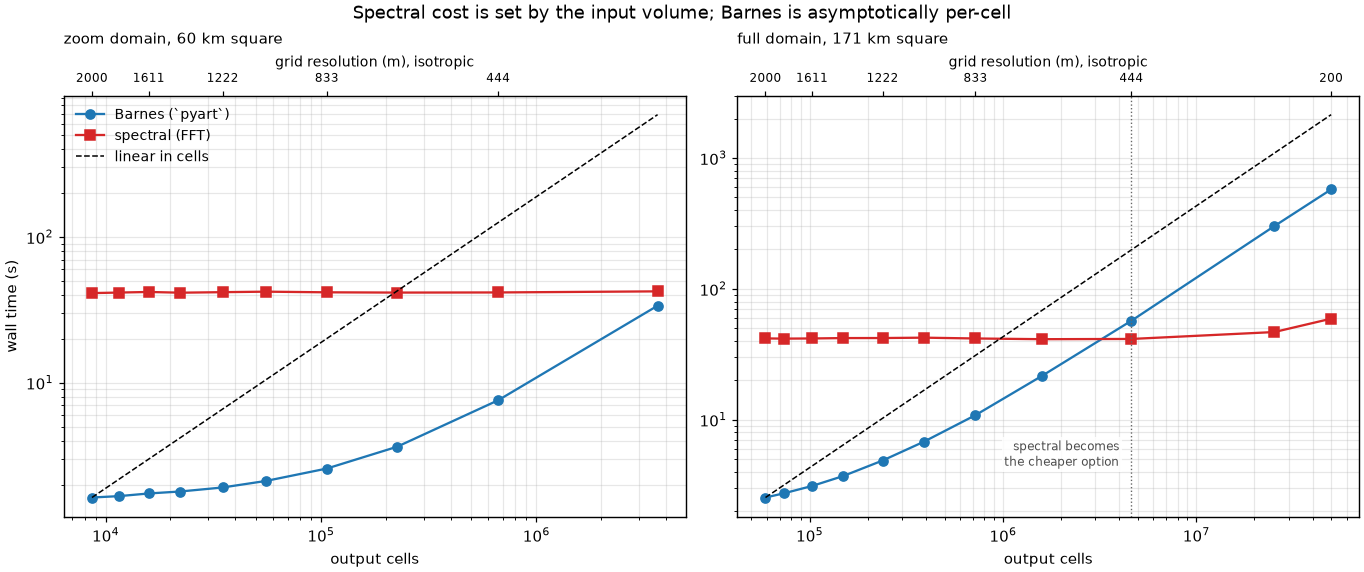

In [8]:
import matplotlib.pyplot as plt

STYLE = {"pyart": ("#1f77b4", "o", "Barnes (`pyart`)"),
         "spectral": ("#d62728", "s", "spectral (FFT)")}

def resolution_axis(ax, sub, every=2):
    """Second x axis labelled in resolution.

    Ticks sit at the MEASURED cell counts rather than at a closed-form inversion of
    resolution: each axis length is round(span / res) + 1, so the smooth formula
    span_z * span_h**2 / res**3 is off by up to 22% at the coarse end.
    """
    top = ax.twiny()
    top.set_xscale("log")
    top.set_xlim(ax.get_xlim())
    shown = sub.iloc[::every]
    top.set_xticks(list(shown.cells))
    top.set_xticklabels([f"{r:.0f}" for r in shown.res_m], fontsize=8)
    top.set_xlabel("grid resolution (m), isotropic", fontsize=9)
    top.tick_params(axis="x", which="minor", top=False)
    return top

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.2), constrained_layout=True)
for ax, name in zip(axes, DOMAINS):
    sub = ramp[ramp.domain == name].sort_values("cells")
    for method, (colour, marker, label) in STYLE.items():
        ax.plot(sub.cells, sub[f"{method}_s"], marker=marker, color=colour,
                ls="-", label=label)
    reference = sub.pyart_s.iloc[0] * sub.cells / sub.cells.iloc[0]
    ax.plot(sub.cells, reference, "k--", lw=1, label="linear in cells")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("output cells")
    ax.grid(alpha=0.3, which="both")
    resolution_axis(ax, sub)
    side_km = 2 * DOMAINS[name]["half"] / 1e3
    ax.set_title(f"{name} domain, {side_km:.0f} km square", fontsize=10, loc="left",
                 pad=34)

axes[0].set_ylabel("wall time (s)")
axes[0].legend(frameon=False, fontsize=9, loc="upper left")

sub = ramp[ramp.domain == "full"].sort_values("cells")
crossing = sub[sub.spectral_s < sub.pyart_s]
if len(crossing):
    axes[1].axvline(crossing.cells.iloc[0], color="0.4", lw=0.9, ls=":")
    axes[1].annotate("spectral becomes\nthe cheaper option",
                     xy=(crossing.cells.iloc[0], sub.pyart_s.min()),
                     xytext=(-8, 18), textcoords="offset points",
                     ha="right", va="bottom", fontsize=8, color="0.3",
                     bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))

fig.suptitle("Spectral cost is set by the input volume; Barnes is asymptotically "
             "per-cell", fontsize=11.5)
fig.savefig("figures/gridding_performance.png", dpi=130)

The dashed line is proportionality to cell count. On the zoom domain both traces sit far
below it and the two look like different kinds of algorithm. On the full domain the
Barnes trace bends up to run parallel with it at the fine end, while the spectral trace
stays flat -- and they cross.


## 7. What the two produce

Same volume, same extent, at 1500 m and 500 m -- on **both** domains. The zoom panels
show the storm structure; the full-domain panels show what the two operators do to a
whole scan, including the regions between cones far from the radar.

Slice indices come from the data in each domain separately -- the level with the most
echo above 30 dBZ, and the row through it -- rather than being fixed by hand.


In [9]:
def slice_grids(domain, resolutions=(1500.0, 500.0)):
    """Grid the domain with both methods at each resolution, keeping the arrays."""
    out = {}
    for resolution in resolutions:
        shape = grid_shape_for(domain, resolution)
        entry = {"shape": shape}
        for method in ("pyart", "spectral"):
            kwargs = BARNES_KW if method == "pyart" else SPECTRAL_KW
            started = time.time()
            grid = grid_volume(radar, grid_shape=shape, grid_limits=domain["limits"],
                               method=method, **kwargs)
            entry[method] = {
                "z": np.ma.filled(grid.fields["reflectivity"]["data"].astype(float),
                                  np.nan),
                "x": grid.x["data"].copy(), "y": grid.y["data"].copy(),
                "levels": grid.z["data"].copy(), "t": time.time() - started}
            del grid
        out[resolution] = entry
        print(f"  {resolution:6.0f} m {str(shape):18s} "
              f"barnes {entry['pyart']['t']:5.2f} s   "
              f"spectral {entry['spectral']['t']:6.2f} s")
    return out

def slice_targets(entry):
    """Level with the most echo above 30 dBZ *where both methods have data*.

    Taking the level from one method alone picks its own best case. With a radius of
    influence that reaches, Barnes fills the lowest level densely -- it finds gates
    below the lowest cone -- while the spectral path is nearly empty there, since at
    range the lowest cone is already above 500 m. Choosing on the Barnes grid would
    therefore select the one level where the comparison is least informative.

    Counting only cells finite in BOTH makes the choice symmetric.
    """
    barnes, spectral = entry["pyart"]["z"], entry["spectral"]["z"]
    both = np.isfinite(barnes) & np.isfinite(spectral)
    strong = both & (barnes > 30)
    k = int(np.argmax([int(strong[i].sum()) for i in range(strong.shape[0])]))
    j = int(np.argmax(strong[k].sum(axis=1)))
    return entry["pyart"]["levels"][k], entry["pyart"]["y"][j]

SLICES = {}
for name, domain in DOMAINS.items():
    print(f"--- {name} domain ---")
    SLICES[name] = slice_grids(domain)
    z_t, y_t = slice_targets(SLICES[name][500.0])
    DOMAINS[name]["z_target"], DOMAINS[name]["y_target"] = z_t, y_t
    print(f"  slices at z = {z_t / 1e3:.2f} km, y = {y_t / 1e3:+.2f} km\n")

--- zoom domain ---
    1500 m (11, 41, 41)       barnes  1.73 s   spectral  40.14 s
     500 m (32, 121, 121)     barnes  5.72 s   spectral  37.72 s
  slices at z = 1.99 km, y = -3.54 km

--- full domain ---
    1500 m (10, 115, 115)     barnes  3.42 s   spectral  38.38 s
     500 m (28, 343, 343)     barnes 41.73 s   spectral  38.56 s
  slices at z = 2.98 km, y = -4.00 km



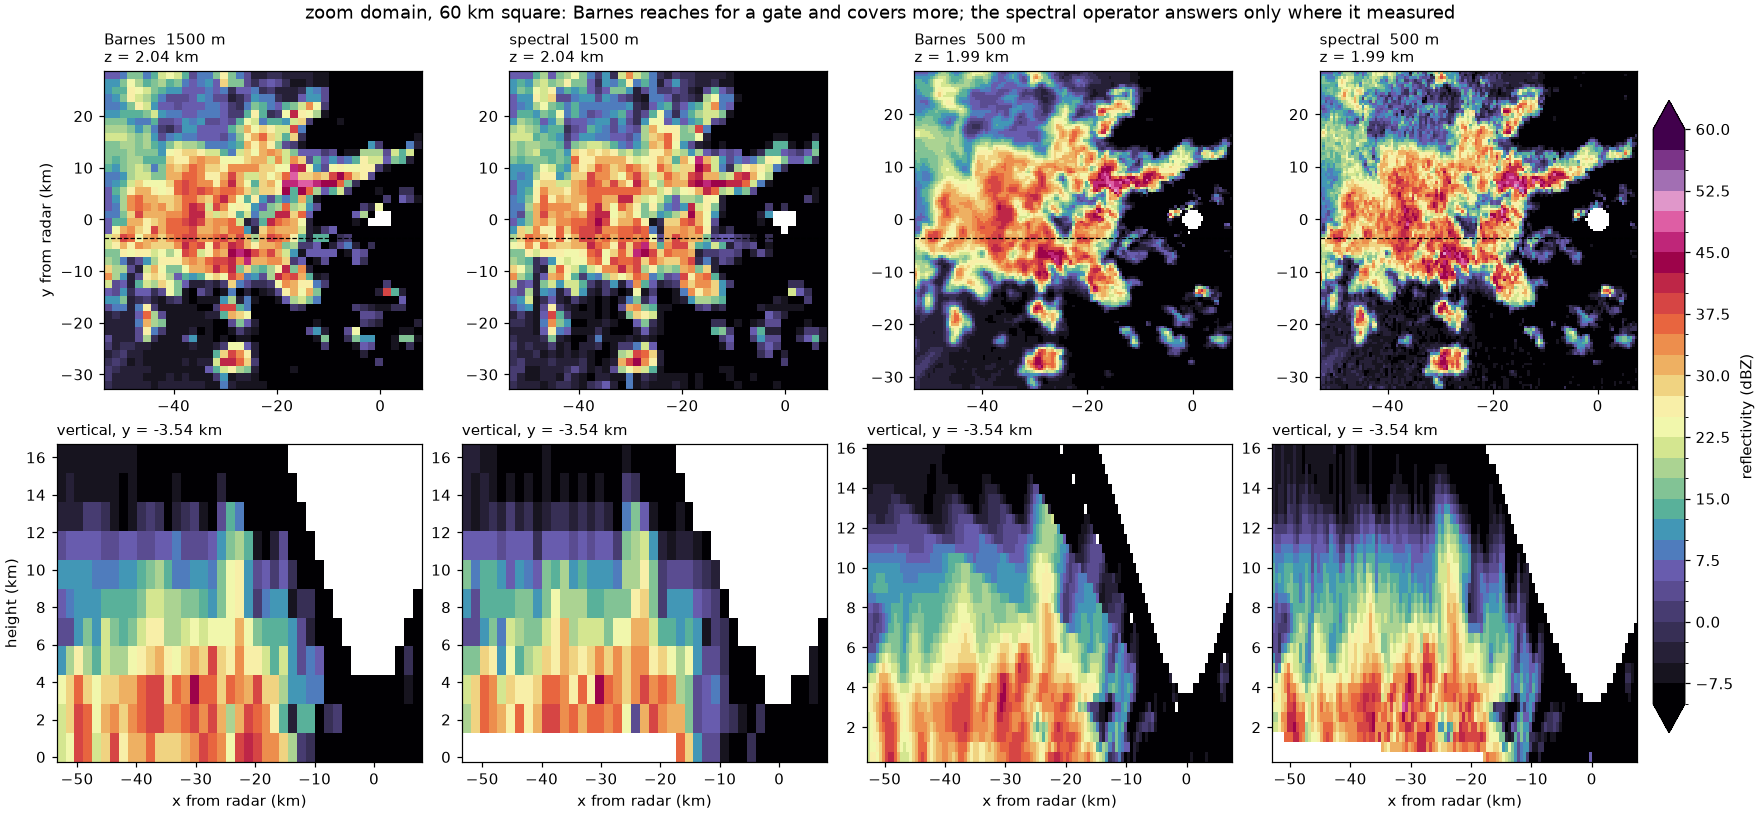

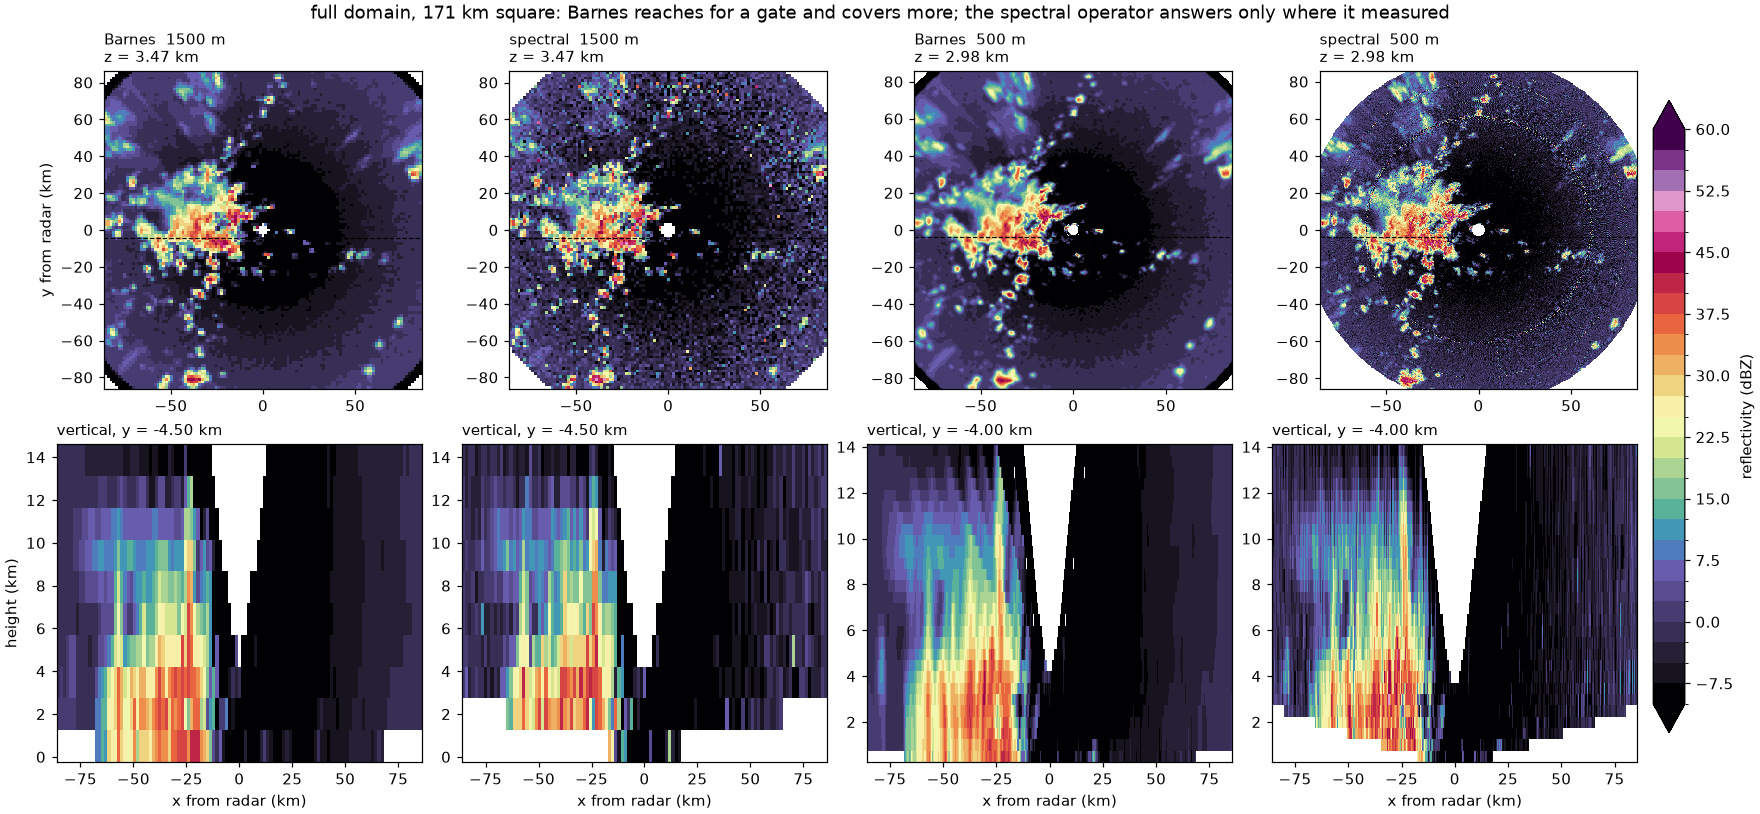

In [10]:
from matplotlib.colors import BoundaryNorm

LEVELS = np.arange(-10, 62, 2.5)
NORM = BoundaryNorm(LEVELS, 256)

def nearest(axis, value):
    return int(np.argmin(np.abs(axis - value)))

def slice_figure(name, filename):
    """Horizontal and vertical slices, both methods, two resolutions."""
    domain = DOMAINS[name]
    z_target, y_target = domain["z_target"], domain["y_target"]
    entries = SLICES[name]

    fig, axes = plt.subplots(2, 4, figsize=(16, 7.4), constrained_layout=True)
    for col, (resolution, method) in enumerate(
            [(1500.0, "pyart"), (1500.0, "spectral"),
             (500.0, "pyart"), (500.0, "spectral")]):
        entry = entries[resolution][method]
        x_km, y_km, z_km = entry["x"] / 1e3, entry["y"] / 1e3, entry["levels"] / 1e3
        k = nearest(entry["levels"], z_target)
        j = nearest(entry["y"], y_target)

        ax = axes[0, col]
        mesh = ax.pcolormesh(x_km, y_km, np.ma.masked_invalid(entry["z"][k]),
                             cmap="ChaseSpectral", norm=NORM, shading="nearest")
        ax.axhline(entry["y"][j] / 1e3, color="k", lw=0.8, ls="--")
        ax.set_aspect("equal")
        ax.set_title(f"{'Barnes' if method == 'pyart' else 'spectral'}  "
                     f"{resolution:.0f} m\nz = {z_km[k]:.2f} km",
                     fontsize=9.5, loc="left")
        if col == 0:
            ax.set_ylabel("y from radar (km)")

        ax = axes[1, col]
        ax.pcolormesh(x_km, z_km, np.ma.masked_invalid(entry["z"][:, j, :]),
                      cmap="ChaseSpectral", norm=NORM, shading="nearest")
        ax.set_xlabel("x from radar (km)")
        ax.set_title(f"vertical, y = {y_km[j]:+.2f} km", fontsize=9.5, loc="left")
        if col == 0:
            ax.set_ylabel("height (km)")

    side_km = 2 * domain["half"] / 1e3
    fig.colorbar(mesh, ax=axes, extend="both", fraction=0.02, pad=0.01,
                 label="reflectivity (dBZ)")
    fig.suptitle(f"{name} domain, {side_km:.0f} km square: Barnes reaches for a gate "
                 f"and covers more; the spectral operator answers only where it measured",
                 fontsize=11.5)
    fig.savefig(filename, dpi=130)
    return fig

slice_figure("zoom", "figures/gridding_slices_zoom.png")
slice_figure("full", "figures/gridding_slices_full.png")

## 8. Where the two genuinely differ: reach

With a radius of influence that spans the cone separation, Barnes almost never leaves an
interior hole -- a handful per section rather than hundreds. The difference between the
operators is no longer whether columns have gaps. It is **where each is willing to
answer**.

Barnes reaches until it finds a gate: below the lowest cone, above the highest, and
past the last recorded range. Vertical assembly interpolates only between the two cones
that bracket a target height, and flags every cell it declines.

Interior holes are still the cleanest single number, so they are counted here -- but note
how small both are now compared with what the default radius produces.


In [11]:
def interior_holes(section):
    """NaN cells with valid data both above and below them in the same column."""
    total = 0
    for column in range(section.shape[1]):
        finite = np.isfinite(section[:, column])
        if finite.sum() < 2:
            continue
        low = int(np.argmax(finite))
        high = len(finite) - 1 - int(np.argmax(finite[::-1]))
        total += int((~finite[low:high + 1]).sum())
    return total

for name, domain in DOMAINS.items():
    entry = SLICES[name][500.0]
    j = nearest(entry["pyart"]["y"], domain["y_target"])
    print(f"--- {name} domain, 500 m ---")
    for method in ("pyart", "spectral"):
        section = entry[method]["z"][:, j, :]
        levels = entry[method]["levels"]
        aloft = levels > 4000
        per_level = np.array([np.isfinite(section[i]).mean()
                              for i in range(len(levels))])
        print(f"  {method:9s} slice filled {np.isfinite(section).mean():6.1%}   "
              f"above 4 km, per-level fill spans "
              f"{per_level[aloft].min():5.1%}-{per_level[aloft].max():5.1%}   "
              f"interior holes: {interior_holes(section):5d}")

--- zoom domain, 500 m ---
  pyart     slice filled  80.9%   above 4 km, per-level fill spans 62.8%-92.6%   interior holes:     6
  spectral  slice filled  74.9%   above 4 km, per-level fill spans 58.7%-88.4%   interior holes:     0
--- full domain, 500 m ---
  pyart     slice filled  93.1%   above 4 km, per-level fill spans 85.7%-98.5%   interior holes:     6
  spectral  slice filled  84.8%   above 4 km, per-level fill spans 82.8%-96.8%   interior holes:     0


Zero interior holes against several hundred. That is the clearest practical argument for
the spectral path: if the next step is a vertical integral, a gradient, or anything that
reads a column, holes between the cones are not a cosmetic problem.

The cost is stated honestly in the ringing above — a band-limited interpolant overshoots
at a sharp edge where an average cannot.

## 9. Range, coverage, and what lies beyond the last gate

An average cannot exceed its inputs; a band-limited interpolant can. On the zoom domain
that shows up as a few dB of overshoot; on the full domain it is far worse in a small
number of cells.

The full domain also exposes something the zoom cannot: it extends past the furthest
gate the datastream records, so the two operators can be compared where there is no
measurement at all.


In [12]:
observed = np.ma.filled(radar.fields["reflectivity"]["data"].astype(float), np.nan)
print(f"observed gates: min {np.nanmin(observed):6.1f}  "
      f"max {np.nanmax(observed):6.1f} dBZ\n")

print(f"{'domain':6s} {'res':>6}  {'method':9s} {'min':>7} {'max':>7} "
      f"{'filled':>7} {'>50 dBZ':>8}")
for name in DOMAINS:
    for resolution in (1500.0, 500.0):
        for method in ("pyart", "spectral"):
            values = SLICES[name][resolution][method]["z"]
            print(f"{name:6s} {resolution:6.0f}  {method:9s} "
                  f"{np.nanmin(values):7.1f} {np.nanmax(values):7.1f} "
                  f"{np.isfinite(values).mean():7.1%} "
                  f"{int(np.nansum(values > 50)):8d}")

observed gates: min  -80.0  max   68.0 dBZ

domain    res  method        min     max  filled  >50 dBZ
zoom     1500  pyart       -25.6    55.6   93.8%        7
zoom     1500  spectral    -50.5    52.5   84.9%        3
zoom      500  pyart       -35.2    57.1   93.9%      174
zoom      500  spectral    -61.6    66.6   88.2%      319
full     1500  pyart       -80.0    53.9   93.9%        8
full     1500  spectral   -117.8   168.9   81.7%       43
full      500  pyart       -80.0    57.9   97.1%      177
full      500  spectral   -241.4   268.3   84.8%     1292


Two things to read off, and the first inverts what a crippled radius of influence
would suggest. With a radius that actually spans the cone separation, **Barnes fills
more of the domain at every height** -- it reaches until it finds a gate, including
above the highest tilt, below the lowest, and past the last recorded range. The
spectral path fills less because it declines to extrapolate beyond the cones that
bracket a target height.

Second, the spectral path can overshoot the observed range at a sharp edge, which an
average cannot by construction.

Neither is a defect. They are the two sides of the same property: one operator answers
everywhere and is silent about where the answer came from, the other answers only where
it measured and says so.


The spectral path produces values outside anything physical -- hundreds of dBZ -- in a
tiny fraction of cells. They sit **inside** the coverage disc, not at the corners, so
this is interpolant ringing where the sampling is marginal, not an edge-of-domain
artefact. The zoom domain contains none of them, which is precisely why it is worth
running the wider test.

The practical response is to clip or mask on a physical ceiling before using a spectral
grid for anything aggregated. The count is small enough that it will not move a mean,
and large enough that it will destroy a maximum.

In [13]:
CEILING = 80.0  # dBZ; nothing meteorological approaches this

print(f"{'domain':6s} {'res':>6}  cells |Z| > {CEILING:.0f} dBZ    "
      f"fraction      where\n")
for name in DOMAINS:
    for resolution in (1500.0, 500.0):
        entry = SLICES[name][resolution]["spectral"]
        values = entry["z"]
        extreme = np.abs(values) > CEILING
        if extreme.any():
            _, j_idx, i_idx = np.where(extreme)
            ranges = np.hypot(entry["x"][i_idx], entry["y"][j_idx]) / 1e3
            where = f"{ranges.min():.0f}-{ranges.max():.0f} km from radar"
        else:
            where = "-"
        print(f"{name:6s} {resolution:6.0f}  {int(extreme.sum()):11d}        "
              f"{extreme.mean():9.4%}   {where}")

print(f"\nradar maximum range: {radar.range['data'][-1] / 1e3:.1f} km")

# The band between the recorded and unambiguous range: no gate exists out there at all.
print(f"\n--- beyond the last recorded gate ({R_RECORDED / 1e3:.2f} km) ---")
for name in DOMAINS:
    entry = SLICES[name][500.0]
    grid_x, grid_y = np.meshgrid(entry["pyart"]["x"], entry["pyart"]["y"], indexing="xy")
    outside = np.hypot(grid_x, grid_y) > R_RECORDED
    if not outside.any():
        print(f"{name:6s} entirely inside the recorded range")
        continue
    k = nearest(entry["pyart"]["levels"], DOMAINS[name]["z_target"])
    for method in ("pyart", "spectral"):
        level = entry[method]["z"][k]
        print(f"{name:6s} {method:9s} {np.isfinite(level[outside]).mean():6.1%} "
              f"of {int(outside.sum())} cells filled")

domain    res  cells |Z| > 80 dBZ    fraction      where

zoom     1500            0          0.0000%   -
zoom      500            0          0.0000%   -
full     1500           22          0.0166%   60-92 km from radar
full      500          659          0.0200%   17-112 km from radar

radar maximum range: 113.3 km

--- beyond the last recorded gate (113.35 km) ---
zoom   entirely inside the recorded range
full   pyart      52.9% of 1020 cells filled
full   spectral    0.0% of 1020 cells filled


The last row is the one worth pausing on. Beyond the furthest gate the file contains,
there is no measurement at any elevation -- and Barnes returns a value in **half** of
those cells anyway. It is the same reach that closes the inter-cone gaps, pointed
outward: a radius of influence large enough to span a cone separation is also large
enough to find a gate 7 km inside the range limit and use it there.

Neither behaviour is wrong. But a domain sized on the instrument rather than on the
file makes the difference visible, and a statistic taken over the whole square will
include those cells unless you mask on range yourself.


## Summary

- **The radius of influence is a real choice, not a default to accept.** Py-ART's
  `roi_func="dist_beam"` is a nearly fixed length, so past the range where the tilt
  separation exceeds it, columns develop interior holes -- hundreds per section. A radius
  that grows with height removes almost all of them, at the cost of averaging over a
  larger neighbourhood and taking longer. Everything else on this page moves with that
  choice, including the crossover resolution and which operator covers more.
- **Test scaling on a domain large enough to reach the asymptote.** On a 60 km box
  Barnes looks lattice-insensitive; on the full inscribed square its local exponent
  climbs to near one and it is plainly per-cell. The small domain gives the wrong answer.
- **Spectral cost is set by the input volume, not the output lattice.** Nearly flat
  across several hundred fold in cell count; halving the rays halves the time. Budget on
  sweep count.
- **The two cross over.** Barnes is far cheaper at kilometre scale and the more expensive
  one at the fine end. Neither is simply faster; the crossover is printed above.
- **Size the domain on the instrument, not the file.** The datastream stops short of the
  unambiguous range, and in that band Barnes still returns a value in about half the
  cells while the spectral path returns none -- the same reach that closes the gaps,
  pointed outward.
- **Determine the grid top from the data**, with a criterion robust to sidelobe.
- **Barnes answers everywhere it can reach; the spectral path answers where it measured
  and flags the rest.** Barnes fills more at every height once its radius reaches. That
  is a difference in what a filled cell *means*, not a difference in quality.
- **Check a spectral grid for out-of-range values before aggregating.** A small fraction
  of cells reach implausible dBZ on the full domain, inside coverage. They will not move
  a mean and will destroy a maximum.
- **Wall-clock timings need an outlier guard, and a physical one.** Earlier runs of this
  notebook reported a spectral step at 25x and a Barnes step at 3x their true cost, from
  unrelated machine load. Neither operator can be worse than linear in output cells, so
  the ramp re-measures any point exceeding twice the linear prediction from the previous
  one -- a bound that holds for both methods, unlike a running median, which is only
  meaningful for the flat series.


## References

### Method

The spectral operator is described in section 2. One reference is named in
`radar-palette`'s source; the rest are the standard sources for methods the code
implements without citing them, identified by reading the implementation. All DOIs
below were resolved through CrossRef.

**Non-uniform FFT and the azimuth solve**

- Dutt, A.; Rokhlin, V. (1993). Fast Fourier Transforms for Nonequispaced Data.
  *SIAM Journal on Scientific Computing*, **14**(6), 1368–1393.
  doi:[10.1137/0914081](https://doi.org/10.1137/0914081)
- Fessler, J. A.; Sutton, B. P. (2003). Nonuniform fast Fourier transforms using
  min-max interpolation. *IEEE Transactions on Signal Processing*, **51**(2), 560–574.
  doi:[10.1109/TSP.2002.807005](https://doi.org/10.1109/tsp.2002.807005) — the
  adjoint-is-not-the-inverse distinction that motivates the conjugate-gradient solve.
- Jackson, J. I.; Meyer, C. H.; Nishimura, D. G.; Macovski, A. (1991). Selection of a
  convolution function for Fourier inversion using gridding. *IEEE Transactions on
  Medical Imaging*, **10**(3), 473–478.
  doi:[10.1109/42.97598](https://doi.org/10.1109/42.97598)
- Beatty, P. J.; Nishimura, D. G.; Pauly, J. M. (2005). Rapid gridding reconstruction
  with a minimal oversampling ratio. *IEEE Transactions on Medical Imaging*, **24**(6),
  799–808. doi:[10.1109/TMI.2005.848376](https://doi.org/10.1109/tmi.2005.848376) —
  **the one reference named in the source**, for the Kaiser–Bessel shape parameter.
- Hestenes, M. R.; Stiefel, E. (1952). Methods of conjugate gradients for solving
  linear systems. *Journal of Research of the National Bureau of Standards*, **49**(6),
  409. doi:[10.6028/jres.049.044](https://doi.org/10.6028/jres.049.044)

**Vertical interpolation**

- Fritsch, F. N.; Carlson, R. E. (1980). Monotone Piecewise Cubic Interpolation.
  *SIAM Journal on Numerical Analysis*, **17**(2), 238–246.
  doi:[10.1137/0717021](https://doi.org/10.1137/0717021) — the shape-preserving
  property is why interpolating between cones cannot overshoot into unphysical values.

**Comparison baseline**

- Barnes, S. L. (1964). A Technique for Maximizing Details in Numerical Weather Map
  Analysis. *Journal of Applied Meteorology*, **3**(4), 396–409.
  doi:[10.1175/1520-0450(1964)003<0396:ATFMDI>2.0.CO;2](https://doi.org/10.1175/1520-0450(1964)003%3C0396:ATFMDI%3E2.0.CO;2)

**Implemented but not used here** — `fill_method="gerchberg"` exists; this notebook runs
the default `"edge"` fill.

- Gerchberg, R. W. (1974). Super-resolution through Error Energy Reduction.
  *Optica Acta*, **21**(9), 709–720.
  doi:[10.1080/713818946](https://doi.org/10.1080/713818946)
- Papoulis, A. (1975). A new algorithm in spectral analysis and band-limited
  extrapolation. *IEEE Transactions on Circuits and Systems*, **22**(9), 735–742.
  doi:[10.1109/TCS.1975.1084118](https://doi.org/10.1109/tcs.1975.1084118)

### Software

- Helmus, J. J.; Collis, S. M. (2016). The Python ARM Radar Toolkit (Py-ART), a Library
  for Working with Weather Radar Data in the Python Programming Language. *Journal of
  Open Research Software*, **4**(1), 25.
  doi:[10.5334/jors.119](https://doi.org/10.5334/jors.119)
- Virtanen, P.; Gommers, R.; Oliphant, T. E.; et al. (2020). SciPy 1.0: fundamental
  algorithms for scientific computing in Python. *Nature Methods*, **17**(3), 261–272.
  doi:[10.1038/s41592-019-0686-2](https://doi.org/10.1038/s41592-019-0686-2)
- `radar-palette` — <https://github.com/DIGR-Legacy/radar-palette>

### Companion notebooks

- [Radar_Volume_Advection_Interpolation.ipynb](Radar_Volume_Advection_Interpolation.ipynb)
- [Advecting_Polarimetric_Variables_carry_fields.ipynb](Advecting_Polarimetric_Variables_carry_fields.ipynb)
